# 4. Lyapunov Exponent Calculations
## Blue/Green Gecko
### Mia-Katrin Kvalsund
### April 2026


Code to support ALIFE 2026 paper:
 > Stovold, Kvalsund, Ludwig, Sharma, Mordvintsev "Visualising the Attractor Landscape of Neural Cellular Automata"

Based on the Colab notebook developed by Mordvintsev et al. for the ["Growing Neural Cellular Automata"](http://distill.pub/2020/growing-ca) article. and J. Stovold's notebook for the ["Neural Cellular Automata can Respond to Signals"](https://github.com/jstovold/ALIFE2023/blob/master/ExternalSignals.ipynb) article at ALIFE 2023.

Code and materials are restricted for any and all use prior to publication; post-publication the code and associated materials are available under the Apache 2.0 license


In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Conv2D

from IPython.display import clear_output
import tqdm
import matplotlib.pyplot as plt

# Dimensionality reduction
from sklearn.decomposition import PCA

clear_output()

# Define and load the network

In [3]:
# no "genome" for external signals:
PARAM_N  = 0                        # Number of genes in the genome
OTHER_N  = 12                       # Number of "empty" spaces in the genome for the CA to communicate between cells
ENV_N    = 1                        # Number of environment channels (not editable by cells)

# Total number of CA state channels (+ 4 for RGBA):
CHANNEL_N = 4 + PARAM_N + OTHER_N + ENV_N

TARGET_PADDING = 2 #15                 # Number of pixels used to pad the target image border
TARGET_SIZE = 30
TARGET_PADDED_SIZE = TARGET_SIZE + TARGET_PADDING * 2

BATCH_SIZE = 12
POOL_SIZE = 1024
CELL_FIRE_RATE = 0.5

EXPERIMENT_TYPE = "Regenerating" #param ["Growing", "Persistent", "Regenerating"]
EXPERIMENT_MAP = {"Growing":0, "Persistent":1, "Regenerating":2}
EXPERIMENT_N = EXPERIMENT_MAP[EXPERIMENT_TYPE]

USE_PATTERN_POOL = [0, 1, 1][EXPERIMENT_N]
DAMAGE_N = [0, 0, 3][EXPERIMENT_N]  # Number of patterns to damage in a batch

BEHAVIOUR_SWITCH=2001               # at what point do we change the way we present the target images to the network?

fix_seed = True                     # for reproducibility
loading_from_file = True
saving = False
add_noise = True

In [4]:
def to_rgba(x):
  return x[..., :4]

def to_alpha(x):
  return tf.clip_by_value(x[..., 3:4], 0.0, 1.0)

def to_rgb(x):
  # assume rgb premultiplied by alpha
  rgb, a = x[..., :3], to_alpha(x)
  return 1.0-a+rgb


def get_channels(x, ch=[5,6,7]):
  rgb, a = x[..., ch], to_alpha(x)
  return 1.0-a+rgb

def get_living_mask(x, threshold = 0.1):
  alpha = x[:, :, :, 3:4]
  return tf.nn.max_pool2d(alpha, 3, [1, 1, 1, 1], 'SAME') > threshold

def get_living(x):
  alpha = x[0, :, :, 3:4]
  return tf.nn.max_pool2d(alpha, 3, [1, 1, 1, 1], 'SAME') > 0.1


def make_seed(size, n=1):
  x = np.zeros([n, size, size, CHANNEL_N], np.float32)
  x[:, size//2, size//2, 3:] = 1.0
  return x



@tf.function
def get_stim(jitter=False):
  size = TARGET_PADDED_SIZE
  stim_x = (size // 2) - (TARGET_SIZE // 10)
  stim_y = (size // 2) - (TARGET_SIZE // 10)

  if jitter:
    rand = tf.random.uniform(shape=(), minval=-1, maxval=1, dtype=tf.int32)
    stim_x = stim_x + rand
    stim_y = stim_y + rand

  return (stim_x, stim_y)

class CAModel(tf.keras.Model):

  def __init__(self, channel_n=CHANNEL_N, fire_rate=CELL_FIRE_RATE):
    super().__init__()
    self.channel_n = channel_n
    self.fire_rate = fire_rate

    self.dmodel = tf.keras.Sequential([
          Conv2D(128, 1, activation=tf.nn.relu, name='layer1'),
          Conv2D(self.channel_n - ENV_N, 1, activation=None,             # no update for ENV_N state
              kernel_initializer=tf.zeros_initializer, name='layer2'),
    ])

    self(tf.zeros([1, 3, 3, channel_n]))  # dummy call to build the model

  # OBS: This function has been changed because package version between colab and my Mac M1 are different. Function has been verified. 
  def perceive(self, x, angle=0.0):
    batch, height, width, in_channels = x.shape

    # Identity kernel
    identify = tf.constant([[0.,0.,0.],
                            [0.,1.,0.],
                            [0.,0.,0.]], dtype=tf.float32)
    # Sobel kernels
    dx = tf.constant([[1,2,1],
                      [0,0,0],
                      [-1,-2,-1]], dtype=tf.float32) / 8.0
    dy = tf.transpose(dx)

    # Rotate kernels 180° (flip both axes)
    identify = tf.reverse(identify, axis=[0,1])
    dx = tf.reverse(dx, axis=[0,1])
    dy = tf.reverse(dy, axis=[0,1])

    # Expand kernels to depthwise shape
    # shape: [3,3,1,1] → will be broadcasted to all input channels
    id_k = identify[:, :, None, None]
    dx_k = dy[:, :, None, None]  # swapped like in your working code
    dy_k = dx[:, :, None, None]

    # Repeat kernels across all input channels (channel_multiplier=1)
    id_k = tf.repeat(id_k, in_channels, axis=2)
    dx_k = tf.repeat(dx_k, in_channels, axis=2)
    dy_k = tf.repeat(dy_k, in_channels, axis=2)

    # Apply depthwise convolution
    y_id = tf.nn.depthwise_conv2d(x, id_k, [1,1,1,1], 'SAME')
    y_dx = tf.nn.depthwise_conv2d(x, dx_k, [1,1,1,1], 'SAME')
    y_dy = tf.nn.depthwise_conv2d(x, dy_k, [1,1,1,1], 'SAME')

    # Reshape and interleave channels: from [H,W,in_channels] → [H,W,in_channels*3]
    # Stack along last axis per channel
    y = tf.reshape(tf.stack([y_id, y_dx, y_dy], axis=-1), [batch, height, width, in_channels*3])

    return y

  @tf.function
  def call(self, x, fire_rate=None, angle=0.0, step_size=1.0, fire_mask=None, return_fire_mask=False):
    pre_life_mask = get_living_mask(x)
    y = self.perceive(x, angle)


    z = self.dmodel(y)
    dx = z*step_size


    if fire_rate is None:
      fire_rate = self.fire_rate

    if fire_mask is None:
      fire_mask = tf.random.uniform(tf.shape(x[:, :, :, :1]))

    update_mask = fire_mask <= fire_rate
    x = x[...,:-ENV_N] + dx * tf.cast(update_mask, tf.float32)
    x = tf.pad(x, tf.constant([[0,0],[0,0],[0,0], [0,ENV_N]]), constant_values=0) # add the environment vars back into the state vector (set to 0)

    post_life_mask = get_living_mask(x)
    life_mask = pre_life_mask & post_life_mask

    if return_fire_mask:
      return x * tf.cast(life_mask, tf.float32), fire_mask
    else:
      return x * tf.cast(life_mask, tf.float32)

ca = CAModel()
ca.load_weights("model/blue_green_salamander/big10000.weights.h5")

2026-03-23 17:54:26.905317: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2026-03-23 17:54:26.905360: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-03-23 17:54:26.905368: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-03-23 17:54:26.905633: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-03-23 17:54:26.905655: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-03-23 17:54:28.274800: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


### Make the seed

In [5]:
h, w = [TARGET_PADDING*2 + TARGET_SIZE] * 2
print(h,w)
seed = np.zeros([h, w, CHANNEL_N], np.float32)
seed[h//2, w//2, 3:]  = 1.0

34 34


In [6]:
x = seed[None, ...]
x = tf.convert_to_tensor(x, dtype=tf.float32)
x.shape

TensorShape([1, 34, 34, 17])

### Run the system for some time

In [11]:
#@title Generate data for Autoencoder

TIMESTEPS = 1000

# record of all NCA states
states = [tf.identity(x)]

for i in tqdm.trange(TIMESTEPS):
  x = ca(x)
  states.append(tf.identity(x))

  if i > 0 and i % 150 == 0:
    stim_x,stim_y = get_stim(jitter=True)
    x = x.numpy()
    x[:,stim_y, stim_x,-ENV_N:] = 1.0
    x = tf.convert_to_tensor(x, dtype=tf.float32)

100%|██████████| 1000/1000 [00:03<00:00, 304.47it/s]


/var/folders/tl/1ptttfgx6txb96127_glc4580000gp/T/ipykernel_4299/1631542195.py:8: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X2[:,0], X2[:,1], s=10, cmap="viridis")


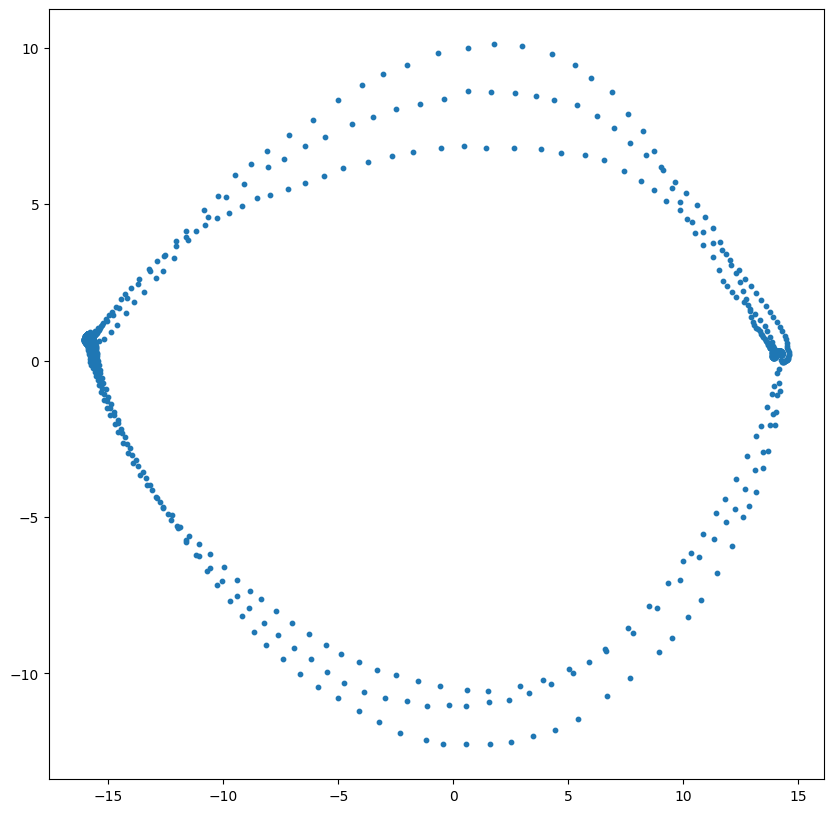

In [12]:
states_np = tf.stack(states).numpy()

T, B, H, W, C = states_np.shape
flattened_states = states_np.reshape(T*B, H*W*C) # [100:] # Discard the first 100 timesteps, seed to green salamander

X2 = PCA(n_components=2).fit_transform(flattened_states)
plt.figure(figsize=(10,10))
plt.scatter(X2[:,0], X2[:,1], s=10, cmap="viridis")
plt.show()

### Define the attractor states, known as green_star and blue_star

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.025955407..1.0297384].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.035257008..1.0308369].


(1, 34, 34, 17)
(1, 34, 34, 17)


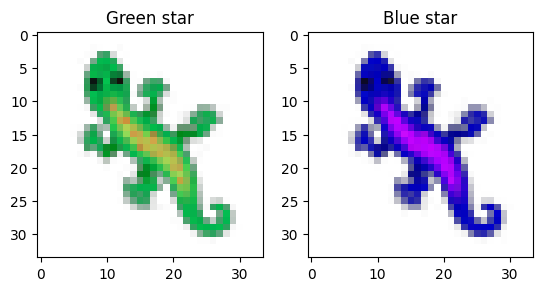

In [13]:
green_t = 149 # This is the timestep right before the signal to change color is sent
green_star = states_np[green_t]
print(green_star.shape)

blue_t = 299 # This is the timestep right before the signal to change color is sent
blue_star = states_np[blue_t]
print(blue_star.shape)

plt.figure()
plt.subplot(1, 2, 1)
plt.title("Green star")
plt.imshow(green_star[0, :, :, :4])

plt.subplot(1, 2, 2)
plt.title("Blue star")
plt.imshow(blue_star[0, :, :, :4])

# Calculating the local Lyapunov exponent for each attractor
https://en.wikipedia.org/wiki/Lyapunov_exponent

I'm using the Wolf algorithm, which was made for recoded data, but it is my understanding that it works for when you can calculate f(x) too. 

I'm using this as reference: https://juliadynamics.github.io/ChaosTools.jl/stable/lyapunovs/#ChaosTools.lyapunov

And this: https://www.youtube.com/watch?v=VGf0nk_vFeA&themeRefresh=1

If lyapunov exponent is > 0, the point is unstable. Perturbations will grow, as the Lyapunov exponent dominates when time goes to infinity. If it is < 0, it is stable. Perturbations will shrink. 

The largest lyapunov exponent is defined as the most positive lyapunov exponent. Every other exponent is more negative than the maximum. 

 50%|█████     | 5/10 [00:48<00:47,  9.59s/it]

We're rescaling


 70%|███████   | 7/10 [01:07<00:28,  9.60s/it]

We're rescaling


 90%|█████████ | 9/10 [01:25<00:09,  9.43s/it]

We're rescaling


100%|██████████| 10/10 [01:35<00:00,  9.51s/it]


-1.5228082


100%|██████████| 10/10 [01:33<00:00,  9.39s/it]


-1.0766485

The maximum Lyapunov exponent for the green attractor is -1.5228082 and the blue is -1.0766485


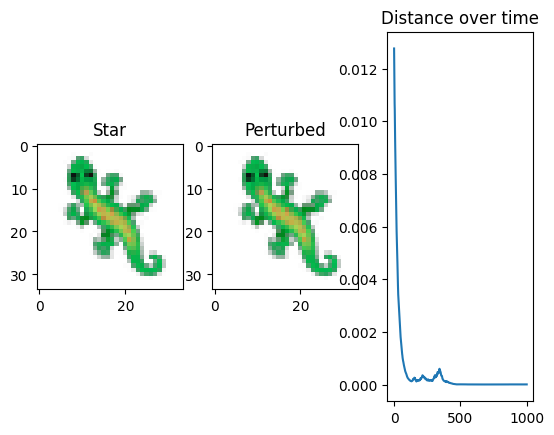

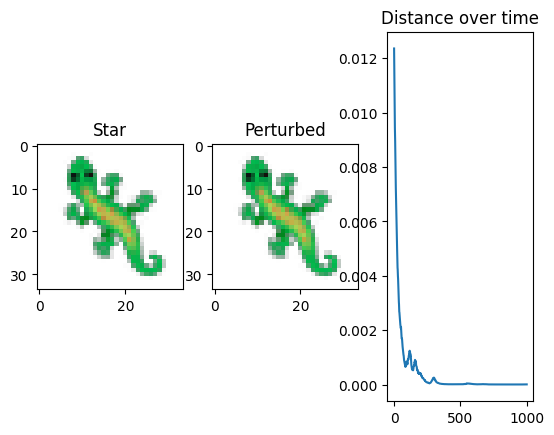

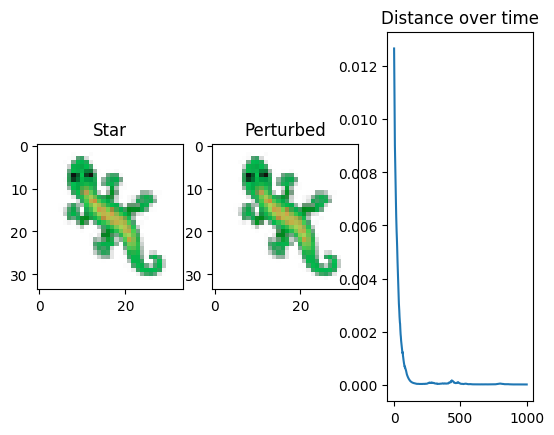

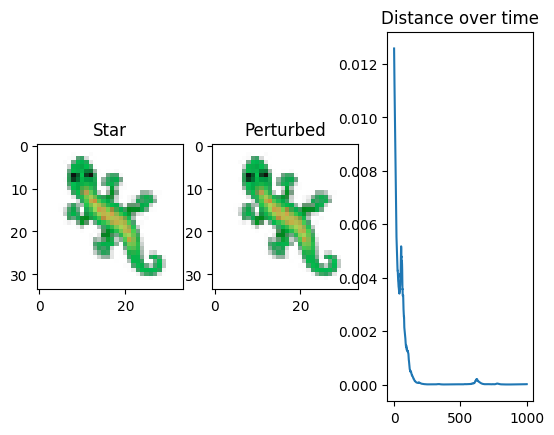

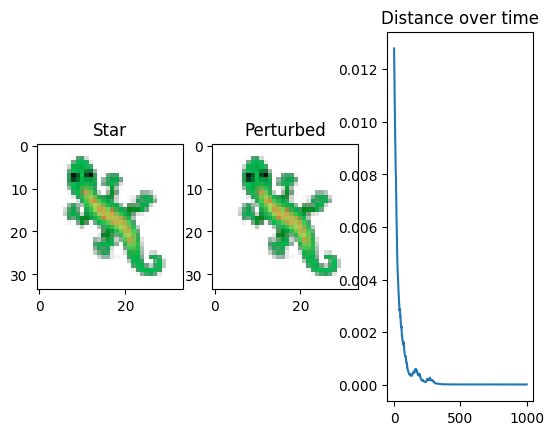

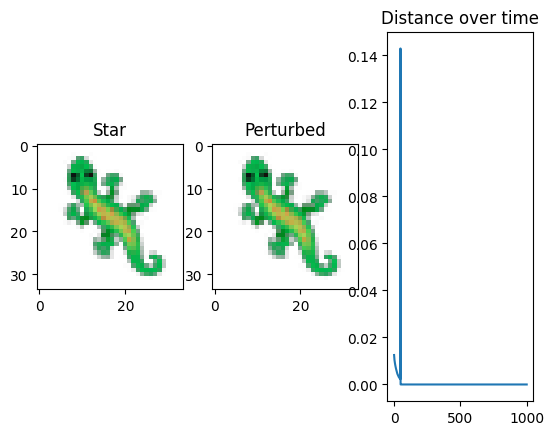

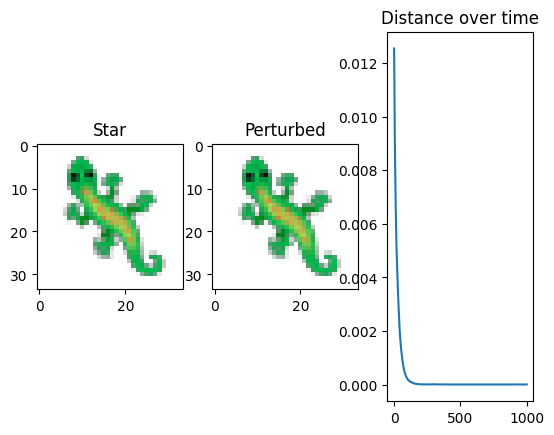

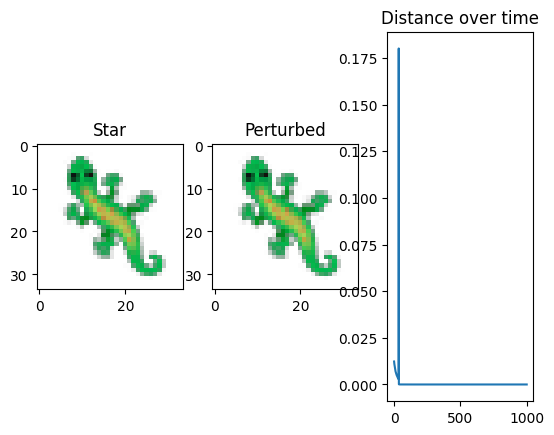

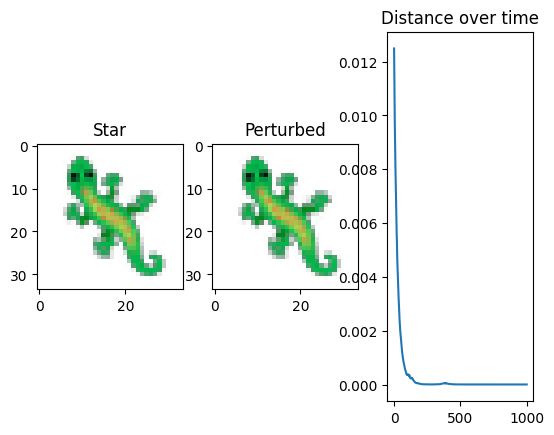

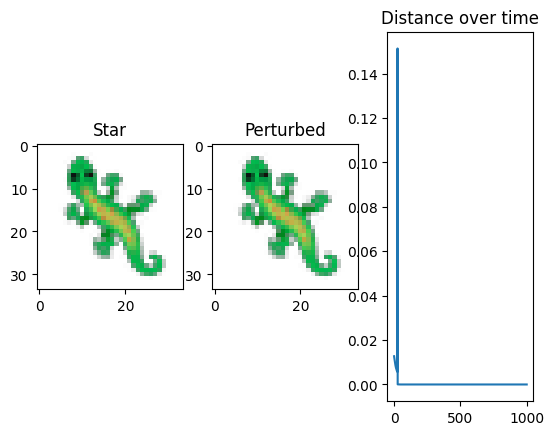

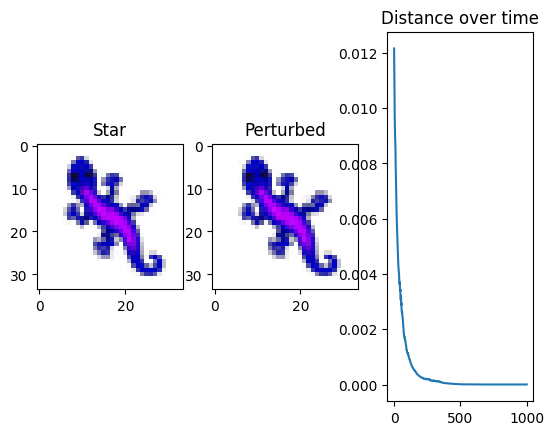

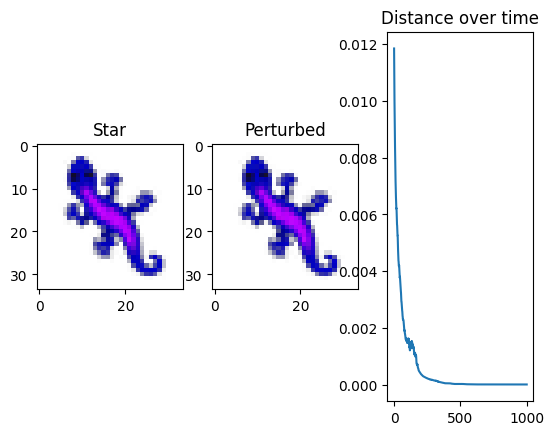

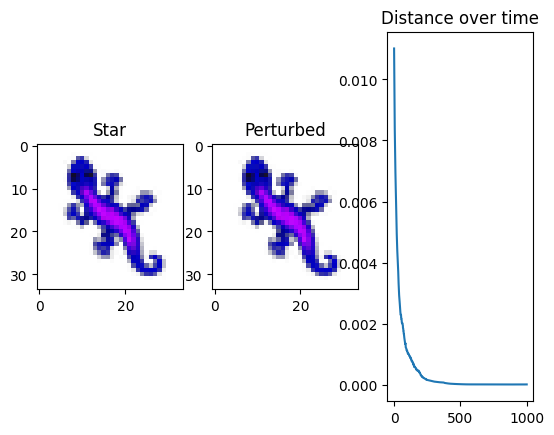

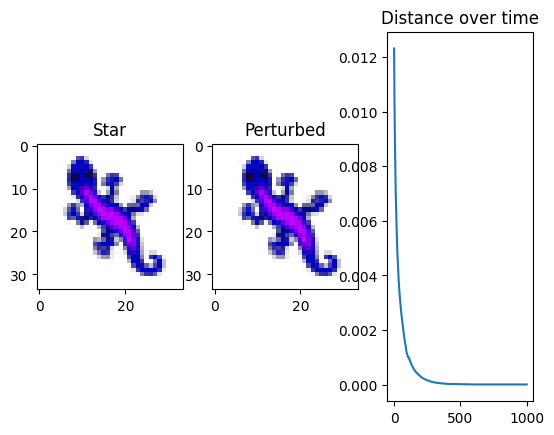

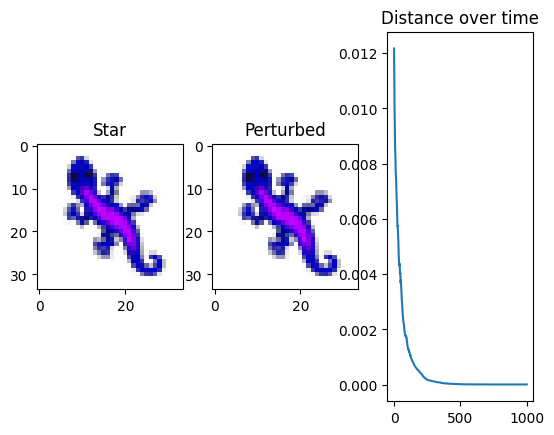

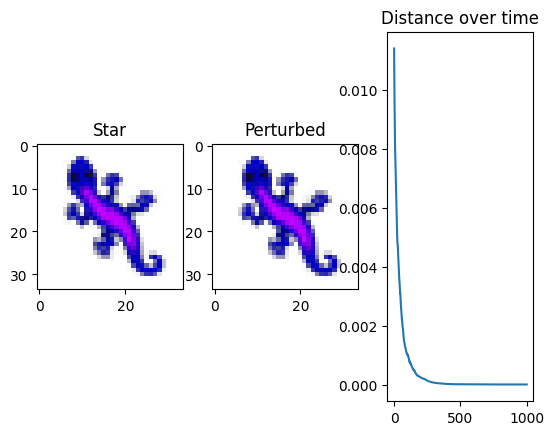

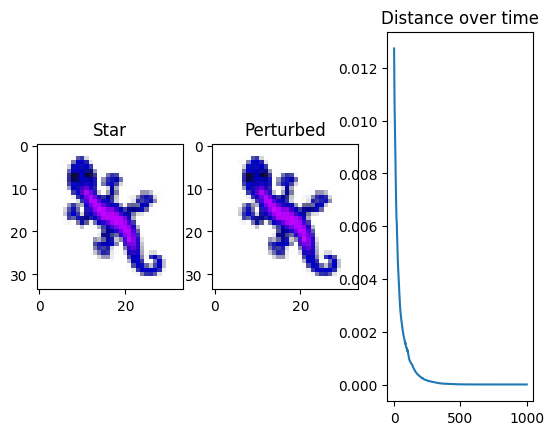

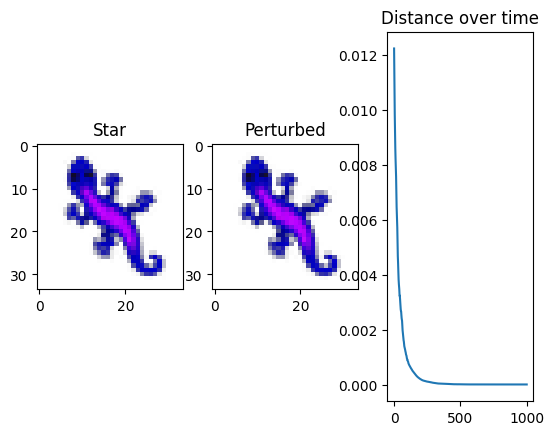

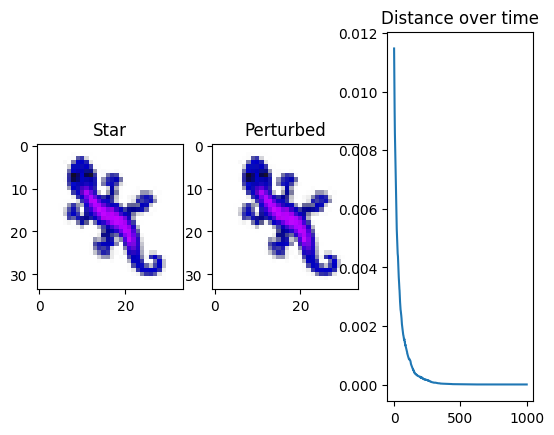

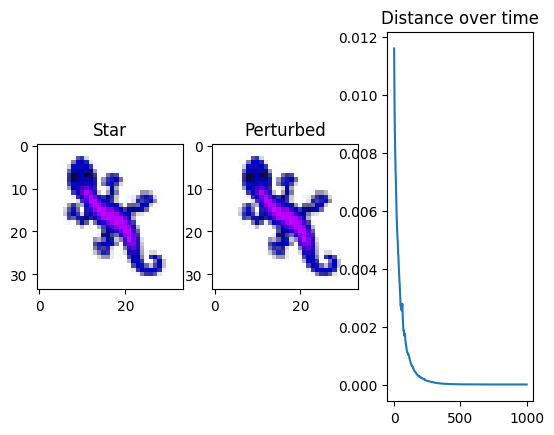

In [19]:
# Lyapunov exponent

def get_lyapunov(model, x_star, d0_lower=1e-3, d0_upper=1e+3, visualize=False, steps=1000):
    x_star = tf.convert_to_tensor(x_star, dtype=tf.float32)

    epsilon = 1e-4
    d0_lower = d0_lower*epsilon
    d0_upper = d0_upper*epsilon

    x = tf.identity(x_star)
    x_perturb = tf.identity(x) + epsilon * tf.random.normal(x.shape)

    lyap_sum = 0.0

    deltas = []

    for _ in range(steps):

        x, fire_mask = model(x, return_fire_mask=True)
        x = tf.identity(x)
        x_perturb = tf.identity(model(x_perturb, fire_mask = fire_mask))

        delta = x_perturb - x
        dist = tf.norm(delta)
        deltas.append(dist)

        lyap_sum += tf.math.log(dist / epsilon)

        # This rescaling is motivated by if we have any sub- or super-critical system where t -> inf, then dist -> ±inf
        # But we are only interested in the rate of change
        if d0_lower > dist or d0_upper < dist:
            print("We're rescaling")
            delta = epsilon * delta / dist
            x_perturb = tf.identity(x) + delta

    lyapunov = lyap_sum / steps

    if visualize:
        plt.figure()
        plt.subplot(1, 3, 1)
        plt.title("Star")
        plt.imshow(x[0, :, :, :4].numpy().clip(0,1))

        plt.subplot(1, 3, 2)
        plt.title("Perturbed")
        plt.imshow(x_perturb[0, :, :, :4].numpy().clip(0,1))

        plt.subplot(1, 3, 3)
        plt.title("Distance over time")
        plt.plot(deltas)

    return lyapunov


n_estimates = 10
lyapunov_green_list = []
for _ in tqdm.trange(n_estimates):
    lyapunov_green_list.append(get_lyapunov(ca, green_star, visualize=True) )
lyapunov_green = np.mean(lyapunov_green_list)
print(lyapunov_green)

lyapunov_blue_list = []
for _ in tqdm.trange(n_estimates):
    lyapunov_blue_list.append(get_lyapunov(ca, blue_star, visualize=True))
lyapunov_blue = np.mean(lyapunov_blue_list)
print(lyapunov_blue)

print("\nThe maximum Lyapunov exponent for the green attractor is", lyapunov_green, "and the blue is", lyapunov_blue)

We get some nice negative values here. Moreover, we see that the distances decay to 0 over time, meaning the attractors are highly stable.

Of course, we are actually not dealing with attractors here. These are saddle points, and as such, there are perturbations that would lead to very high exponent (the road out of the attractor point to the other colored gecko). However, I'd be unlucky to hit that with a random perturbation in multi-dimensional space.